<a href="https://colab.research.google.com/github/bvsvntv/ai-ml-learning/blob/main/notebooks/lang-graph/stm_summarization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [54]:
!pip install -U langchain-openai

In [55]:
from langgraph.graph import StateGraph, END, START, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage, RemoveMessage, AIMessage
from google.colab import userdata
from IPython.display import Image

In [56]:
api_key = userdata.get("OPENAI_API_KEY")
model = ChatOpenAI(api_key=api_key, model="gpt-6-luna")

In [57]:
# chat state
class ChatState(MessagesState):
  summary: str

In [58]:
def summarize_conversation(state: ChatState):
  existing_summary = state["summary"]

  # build summarization prompt
  if existing_summary:
    prompt=(
        f"Existing summary:\n{existing_summary}\n\n"
        "Extend the summary with new conversation above."
    )
  else:
    prompt = "Summarize the conversation above."

  messages_for_summary = state["messages"] + [HumanMessage(content=prompt)]

  response = model.invoke(messages_for_summary)

  # keep only last 2 messages verbatim
  messages_to_delete = state["messages"][:-2]
  cleaned_messages = [RemoveMessage(id=m.id) for m in messages_to_delete]

  return {
      "summary": response.content,
      "messages": cleaned_messages
  }

In [59]:
def chat_node(state: ChatState):
  messages = []

  summary = state["summary"]
  if summary:
    messages.append({
        "role": "system",
        "content": f"Conversation summary:\n{summary}"
    })

  messages.extend(state["messages"])

  print("-"*80)
  for m in messages:
    print(type(m).__name__, ":", m.content)
  print("-"*80)

  response = model.invoke(messages)
  return {"messages": [response]}

In [60]:
def should_summarize(state: ChatState):
  return len(state["messages"]) > 0

In [61]:
# graph
graph = StateGraph(ChatState)

graph.add_node("chat_node", chat_node)
graph.add_node("summarize_node", summarize_conversation)

graph.add_edge(START, "chat_node")
graph.add_conditional_edges("chat_node", should_summarize, {True: "summarize_node", False: END})
graph.add_edge("summarize_node", END)

In [62]:
checkpointer = InMemorySaver()
workflow = graph.compile(checkpointer=checkpointer)

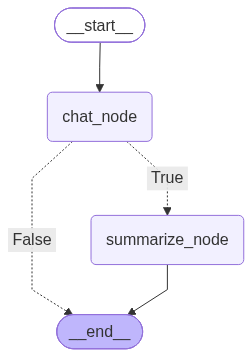

In [63]:
# view graph
Image(workflow.get_graph().draw_mermaid_png())

In [64]:
config = {"configurable": {"thread_id": "thread-1"}}

In [65]:
def run_turn(input: str):
  output = workflow.invoke({"messages": [HumanMessage(content=input)], "summary": ""}, config=config)
  return output

In [66]:
def view_state():
  graph_state = workflow.get_state(config)
  values = graph_state.values

  print("-"*35, "STATE", "-"*35)
  print("SUMMARY: ", values.get("summary", ""))
  print("NO. OF MESSAGES: ", len(values.get("messages", [])))
  print("MESSAGES:")
  for m in values.get("messages", []):
    print(type(m).__name__, ":", m.content)
  print("-"*80)

In [67]:
run_turn("Quantum Physics")
view_state()

--------------------------------------------------------------------------------
HumanMessage : Quantum Physics
--------------------------------------------------------------------------------
----------------------------------- STATE -----------------------------------
SUMMARY:  You asked about quantum physics. I gave a brief overview of its key ideas—quantization, superposition, uncertainty, entanglement, and wave–particle behavior—and mentioned some technologies it enables. I then asked what aspect you’d like to explore further.
NO. OF MESSAGES:  2
MESSAGES:
HumanMessage : Quantum Physics
AIMessage : Quantum physics describes how matter and light behave at very small scales, such as atoms and subatomic particles. Its central ideas include:

- **Quantization:** Some properties, like energy, can take only specific values.
- **Superposition:** A system can be described as a combination of possible states until it is measured.
- **Uncertainty:** Certain pairs of properties—such as posit

In [68]:
run_turn("How is Albert Einstien related?")
view_state()

--------------------------------------------------------------------------------
HumanMessage : Quantum Physics
AIMessage : Quantum physics describes how matter and light behave at very small scales, such as atoms and subatomic particles. Its central ideas include:

- **Quantization:** Some properties, like energy, can take only specific values.
- **Superposition:** A system can be described as a combination of possible states until it is measured.
- **Uncertainty:** Certain pairs of properties—such as position and momentum—cannot both be known with unlimited precision.
- **Entanglement:** Two particles can share linked properties, even when far apart.
- **Wave–particle behavior:** Quantum objects can show both wave-like and particle-like effects.

These ideas underpin technologies such as semiconductors, lasers, and MRI scanners. What would you like to explore—an intuitive introduction, the mathematics, a particular experiment, or a specific concept?
HumanMessage : How is Albert Einst

In [69]:
run_turn("What are some of Einstien's fampus work")
view_state()

--------------------------------------------------------------------------------
HumanMessage : How is Albert Einstien related?
AIMessage : Albert **Einstein** helped lay the foundations of quantum physics. In 1905, he explained the **photoelectric effect** by proposing that light comes in discrete packets of energy, later called **photons**—work for which he received the Nobel Prize.

He also made important contributions to **Bose–Einstein statistics** and predicted a state of matter called a **Bose–Einstein condensate**. At the same time, Einstein questioned whether quantum theory was complete, especially its implications for randomness and entanglement. His famous phrase “spooky action at a distance” referred to that concern.

So, Einstein helped build quantum physics, while also challenging how it should be understood.
HumanMessage : What are some of Einstien's fampus work
--------------------------------------------------------------------------------
-----------------------------